<a href="https://colab.research.google.com/github/nurulfdlharba-dotcom/rf-dengan-threshold/blob/main/main_hasil_1_rf_baru.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Import library

In [3]:
# 1. Library untuk pengolahan data dan numerik
import pandas as pd
import numpy as np

# 2. Library untuk visualisasi data dan grafik evaluasi
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Library untuk pembagian data dan 5-Fold Cross-Validation
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# 4. Library algoritma Random Forest
from sklearn.ensemble import RandomForestClassifier

# 5. Library lengkap untuk evaluasi performa model
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 6. Library untuk menyimpan model
import joblib

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


# 2. Load dataset

In [4]:
# Membaca dataset dari file CSV
df = pd.read_csv('dataset1.csv')

# Menampilkan ukuran dataset (jumlah baris, jumlah kolom)
print("Ukuran dataset (baris, kolom):", df.shape)

# Menampilkan 5 baris pertama untuk memastikan data terbaca dengan benar
print("\n5 baris pertama dataset:")
display(df.head())

Ukuran dataset (baris, kolom): (880, 13)

5 baris pertama dataset:


,N,P,K,pH,EC,OC,S,Zn,Fe,Cu,Mn,B,Output
0,138,8.6,560,7.46,0.62,0.70,5.9,0.24,0.31,0.77,8.71,0.11,0
1,213,7.5,338,7.62,0.75,1.06,25.4,0.30,0.86,1.54,2.89,2.29,0
2,163,9.6,718,7.59,0.51,1.11,14.3,0.30,0.86,1.57,2.70,2.03,0
3,157,6.8,475,7.64,0.58,0.94,26.0,0.34,0.54,1.53,2.65,1.82,0
4,270,9.9,444,7.63,0.40,0.86,11.8,0.25,0.76,1.69,2.43,2.26,1


# 3. Cleaning dataset

In [5]:
# 1. Memilih hanya 5 kolom parameter yang akan digunakan
kolom_pilihan = ['N', 'P', 'K', 'pH', 'EC']
df_clean = df[kolom_pilihan].copy()

# 2. Cek dan hapus data kosong (missing values) jika ada
print("Jumlah missing values sebelum cleaning:\n", df_clean.isnull().sum())
df_clean = df_clean.dropna()

# 3. Cek dan hapus data duplikat
print("\nJumlah baris duplikat sebelum cleaning:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# 4. Hapus nilai yang tidak masuk akal secara fisik (nilai negatif atau pH di luar 0-14)
df_clean = df_clean[
    (df_clean['N'] >= 0) &
    (df_clean['P'] >= 0) &
    (df_clean['K'] >= 0) &
    (df_clean['EC'] >= 0) &
    (df_clean['pH'] >= 0) & (df_clean['pH'] <= 14)
].reset_index(drop=True)

# 5. Menyamakan satuan EC dari dS/m ke µS/cm (dikali 1000) agar sesuai dengan threshold
df_clean['EC'] = df_clean['EC'] * 1000

print("\nUkuran dataset setelah cleaning (baris, kolom):", df_clean.shape)
display(df_clean.head())

Jumlah missing values sebelum cleaning:
 N     0
P     0
K     0
pH    0
EC    0
dtype: int64

Jumlah baris duplikat sebelum cleaning: 16

Ukuran dataset setelah cleaning (baris, kolom): (864, 5)


,N,P,K,pH,EC
0,138,8.6,560,7.46,620.0
1,213,7.5,338,7.62,750.0
2,163,9.6,718,7.59,510.0
3,157,6.8,475,7.64,580.0
4,270,9.9,444,7.63,400.0


# 4. EDA (Exploratory Data Analysis)

In [8]:
# 1. Ringkasan Statistik Deskriptif (Mean, Std, Min, Kuartil, Max)
print("Ringkasan Statistik Deskriptif:")
display(df_clean.describe().round(2))

# Daftar parameter dan warna agar grafik rapi
fitur = ['N', 'P', 'K', 'pH', 'EC']
warna = ['#2b5c8f', '#388e3c', '#f57c00', '#7b1fa2', '#00838f']

Ringkasan Statistik Deskriptif:


,N,P,K,pH,EC
count,864.00,864.00,864.00,864.00,864.00
mean,245.50,14.61,501.05,7.51,543.29
std,77.45,22.16,124.75,0.47,141.81
min,6.00,2.90,11.00,0.90,100.00
25%,201.00,6.80,412.00,7.35,430.00
50%,257.00,8.10,475.00,7.50,545.00
75%,302.50,10.50,581.00,7.63,640.00
max,383.00,125.00,887.00,11.15,950.00


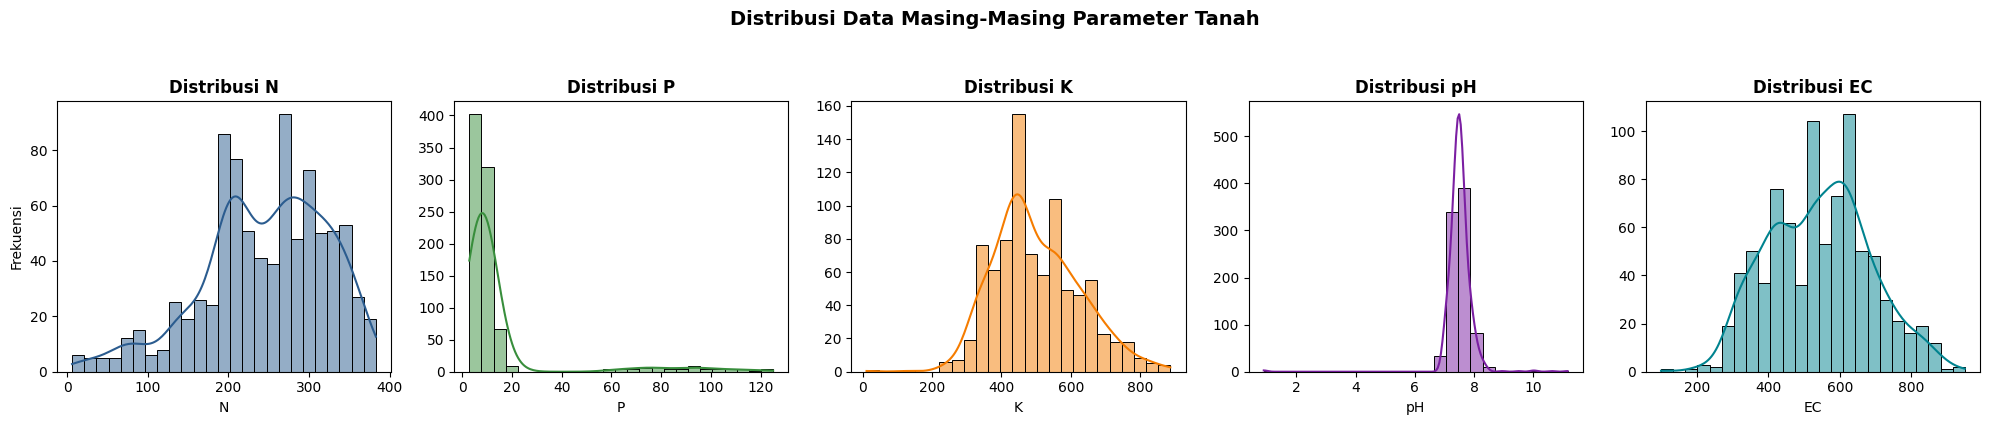

In [9]:
# 2. Visualisasi Distribusi Data (Histogram + KDE)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, col in enumerate(fitur):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color=warna[i], bins=25)
    axes[i].set_title(f'Distribusi {col}', fontweight='bold')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frekuensi' if i == 0 else '')
plt.suptitle('Distribusi Data Masing-Masing Parameter Tanah', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

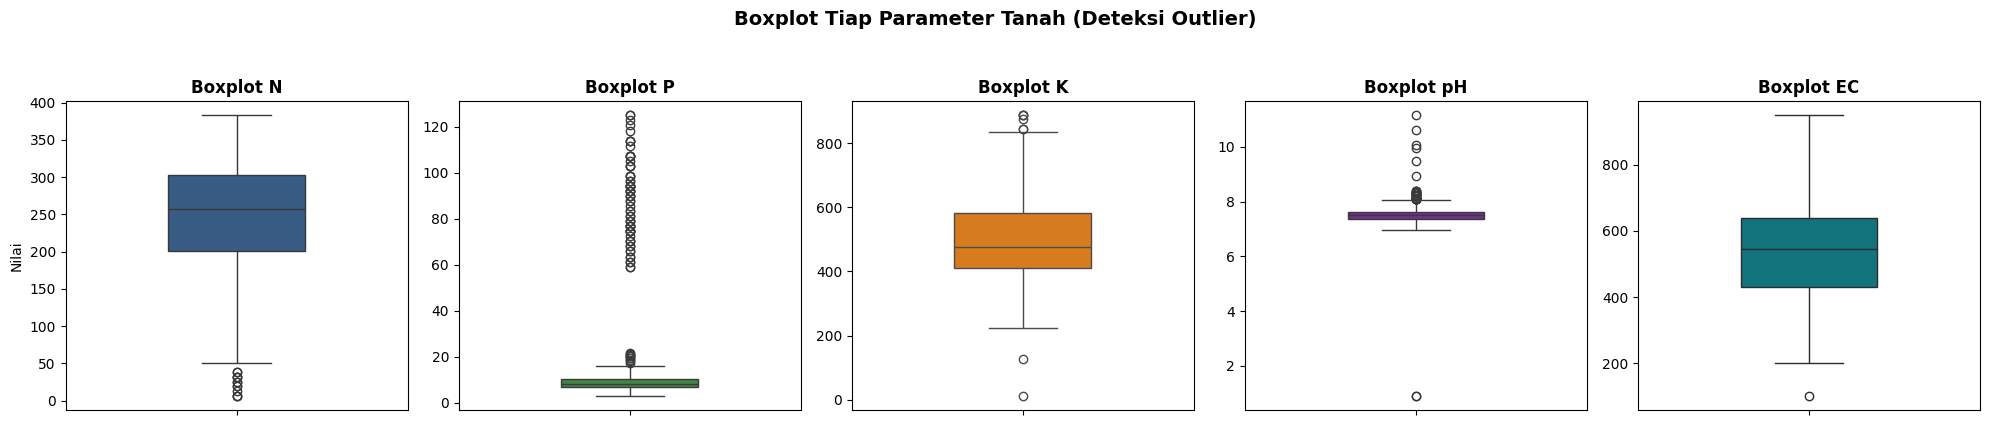

In [10]:
# 3. Visualisasi Boxplot (Deteksi Sebaran & Outlier)
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i, col in enumerate(fitur):
    sns.boxplot(y=df_clean[col], ax=axes[i], color=warna[i], width=0.4)
    axes[i].set_title(f'Boxplot {col}', fontweight='bold')
    axes[i].set_ylabel('Nilai' if i == 0 else '')
plt.suptitle('Boxplot Tiap Parameter Tanah (Deteksi Outlier)', fontsize=14, fontweight='bold', y=1.05)
plt.tight_layout()
plt.show()

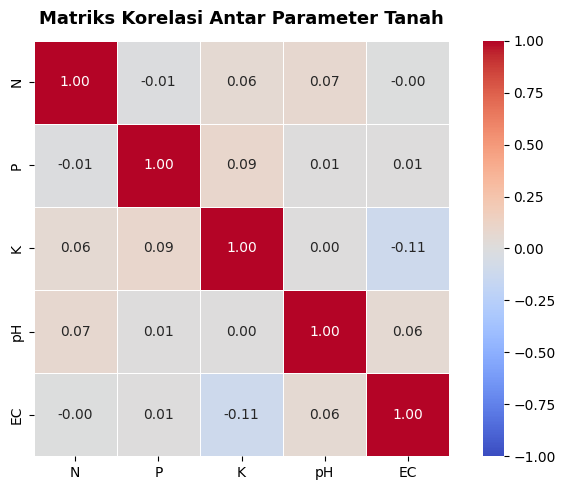

In [11]:
# 4. Visualisasi Korelasi Antar Parameter (Heatmap)
plt.figure(figsize=(7, 5))
korelasi = df_clean.corr()
sns.heatmap(
    korelasi,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)
plt.title('Matriks Korelasi Antar Parameter Tanah', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()